In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 30)
plt.rcParams["figure.figsize"] = (10, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

train = pd.read_csv('data/train-test.csv')
val = pd.read_csv('data/validation.csv')
december_chart_input = pd.read_csv('data/december-chart-inputs.csv')

print(train.shape)
print(val.shape)
print(december_chart_input.shape)



(48000, 14)
(12000, 13)
(31, 7)


# Train Shape and Time Coverage

In [17]:
train.head(5)

,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal,posted_rate
0,TR-000001,Richmond,Baltimore,38.09122,-76.78906,38.16908,-72.74564,274.3,Dry Van,30658.0,2025-01-01,0.95684,2.39595,645.41
1,TR-000002,Richmond,Philadelphia,38.09122,-76.78906,39.22317,-72.96710,280.5,Reefer,17555.0,2025-01-01,0.97623,2.43355,679.97
2,TR-000003,Philadelphia,Green Bay,39.22317,-72.96710,44.30296,-87.52871,967.8,Dry Van,31721.0,2025-01-01,1.00971,1.84491,1802.54
3,TR-000004,Hartford,Atlanta,39.55328,-72.18051,34.84933,-86.28940,965.4,Dry Van,32333.0,2025-01-01,0.94518,1.87712,1827.28
4,TR-000005,Dallas,Nashville,31.83025,-94.38343,35.29479,-88.08915,541.9,Reefer,35183.0,2025-01-01,0.98480,2.56300,1380.28


In [18]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 48000 entries, 0 to 47999
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   load_id       48000 non-null  str    
 1   pickup        48000 non-null  str    
 2   delivery      48000 non-null  str    
 3   pickup_lat    48000 non-null  float64
 4   pickup_lon    48000 non-null  float64
 5   delivery_lat  48000 non-null  float64
 6   delivery_lon  48000 non-null  float64
 7   distance      48000 non-null  float64
 8   equipment     48000 non-null  str    
 9   weight        47700 non-null  float64
 10  date          48000 non-null  str    
 11  market_index  47626 non-null  float64
 12  quote_signal  48000 non-null  float64
 13  posted_rate   48000 non-null  float64
dtypes: float64(9), str(5)
memory usage: 5.1 MB


In [19]:
print("train dates:", train.date.min(), "->", train.date.max())
print("val dates:  ", val.date.min(), "->", val.date.max())
print()
print("val rows in Nov:", (val.date < "2025-12-01").sum())
print("val rows in Dec:", (val.date >= "2025-12-01").sum())
print()
print("columns in train but not val:", set(train.columns) - set(val.columns))

train dates: 2025-01-01 -> 2025-10-31
val dates:   2025-11-01 -> 2025-12-31

val rows in Nov: 5836
val rows in Dec: 6164

columns in train but not val: {'posted_rate'}


Finding : The train date and val date donot overlap. The `posted_rate` is the only column that the train has but the validation does not have.

This is a pure forecasting problem.


# Missing values

In [20]:
miss = pd.DataFrame({
    "train_n": train.isna().sum(),
    "train_pct": (train.isna().mean() * 100).round(2),
    "val_n": val.isna().sum(),
    "val_pct": (val.isna().mean() * 100).round(2),
})
miss[miss.train_n + miss.val_n > 0]


,train_n,train_pct,val_n,val_pct
market_index,374,0.78,249.0,2.08
weight,300,0.62,165.0,1.38


In [21]:
month = train.date.str[:7]
(train.assign(m=month)
      .groupby("m")[["weight", "market_index"]]
      .apply(lambda g: g.isna().mean().mul(100).round(2)))

,weight,market_index
m,,
2025-01,0.69,0.73
2025-02,0.76,0.83
2025-03,0.71,0.87
2025-04,0.42,0.64
2025-05,0.45,0.88
2025-06,0.67,0.88
2025-07,0.59,0.73
2025-08,0.61,0.69
2025-09,0.71,0.66


Finding:
- Only weight and market_index have missing values.
- Training: weight 300 (0.63%), market_index 374 (0.78%).
- Validation: weight 165 (1.38%), market_index 249 (2.08%).
- Other features have no missing values.
- Rows cannot be dropped because predictions are required for all 12,000 load_id values.
- Missing-value indicators will be added for both features.
- Missing values will be filled using the training-set mean, then applied consistently to training, validation, and December data.

# Checking impossible values in the data

In [22]:
for name, df in [("train", train), ("val", val)]:
    print(name)
    print (" negative weights:", (df.weight < 0).sum())
    print (" zero weights:", (df.weight == 0).sum())
    print (" distance <= 0:", (df.distance <= 0).sum())

train
 negative weights: 292
 zero weights: 0
 distance <= 0: 0
val
 negative weights: 145
 zero weights: 0
 distance <= 0: 0


positive weights  mean: 31415  std: 7995
|negative weights| mean: 31724  std: 8263


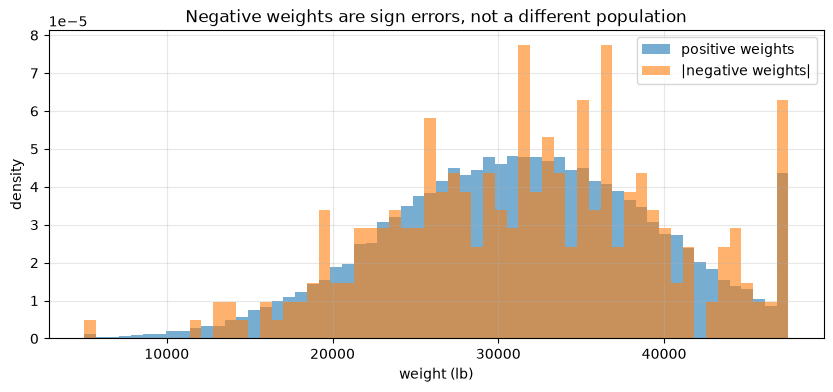

In [23]:
neg = train.weight < 0
print("positive weights  mean: %.0f  std: %.0f" % (train.weight[~neg].mean(), train.weight[~neg].std()))
print("|negative weights| mean: %.0f  std: %.0f" % (train.weight[neg].abs().mean(), train.weight[neg].abs().std()))

fig, ax = plt.subplots()
ax.hist(train.weight[~neg], bins=60, alpha=0.6, label="positive weights", density=True)
ax.hist(train.weight[neg].abs(), bins=60, alpha=0.6, label="|negative weights|", density=True)
ax.set_xlabel("weight (lb)"); ax.set_ylabel("density")
ax.set_title("Negative weights are sign errors, not a different population")
ax.legend();


**Finding.** 292 training rows and 145 validation rows carry a negative weight. Taking the
absolute value puts them on top of the positive distribution: mean 31,724 lb against 31,415 lb.
These are sign errors, not outliers and not a distinct population.

**Decision: `weight = weight.abs()`.** Dropping them would throw away real loads, and in
validation it is not even an option.


# Target Distribution

In [24]:
train.posted_rate.describe(percentiles=[.01, .25, .5, .75, .99]).round(2)

count    48000.00
mean      2373.98
std       1486.49
min         57.22
1%         327.17
25%       1251.55
50%       2030.76
75%       3330.75
99%       5972.83
max      25533.00
Name: posted_rate, dtype: float64

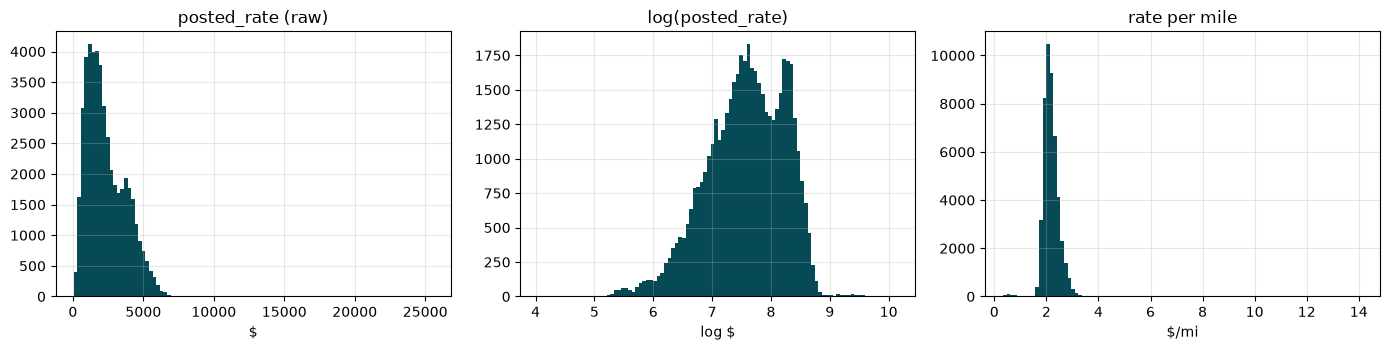

In [25]:
rpm = train.posted_rate / train.distance   # dollars per mile

fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
axes[0].hist(train.posted_rate, bins=100, color="#064A56")
axes[0].set_title("posted_rate (raw)"); axes[0].set_xlabel("$")
axes[1].hist(np.log(train.posted_rate), bins=100, color="#064A56")
axes[1].set_title("log(posted_rate)"); axes[1].set_xlabel("log $")
axes[2].hist(rpm, bins=100, color="#064A56")
axes[2].set_title("rate per mile"); axes[2].set_xlabel("$/mi")
plt.tight_layout();

In [26]:
print("raw  rate  CV: %.3f" % (train.posted_rate.std() / train.posted_rate.mean()))
print("rate/mile  CV: %.3f" % (rpm.std() / rpm.mean()))
print()
print(rpm.describe(percentiles=[.001, .01, .5, .99, .999]).round(3))

raw  rate  CV: 0.626
rate/mile  CV: 0.264

count    48000.000
mean         2.215
std          0.584
min          0.334
0.1%         0.437
1%           1.674
50%          2.145
99%          3.177
99.9%       10.069
max         14.125
dtype: float64


Raw posted_rate ranges from $57 to $25,533 and is strongly right-skewed (CV = 0.626).



Rate per mile is more consistent (CV = 0.264), with the 1st–99th percentile range around $1.67–$3.18 per mile.



The high total price is likely due to a long distance, not necessarily an error.



Decision: Train on log(posted_rate) and transform predictions back to the original scale. Keep distance as a feature and compare this approach with predicting rate per mile.



Outlier handling: Trim extreme rate-per-mile values using the 0.1st and 99.9th percentiles, calculated within each training fold only. Never trim validation data when evaluating model performance.

# Rate against distance

pearson r: 0.9085


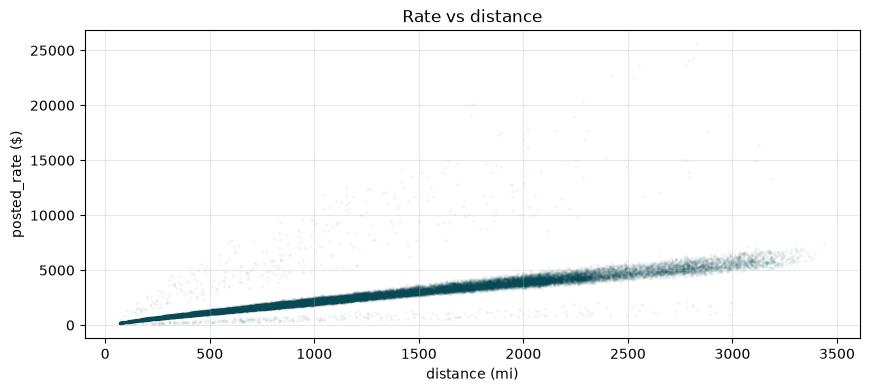

In [27]:
fig, ax = plt.subplots()
ax.scatter(train.distance, train.posted_rate, s=2, alpha=0.03, color="#064A56")
ax.set_xlabel("distance (mi)"); ax.set_ylabel("posted_rate ($)")
ax.set_title("Rate vs distance")
print("pearson r:", round(np.corrcoef(train.distance, train.posted_rate)[0, 1], 4))

In [28]:
bins = pd.cut(train.distance, [0, 250, 500, 750, 1000, 1500, 2000, 2500, 3500])
by_dist = (train.assign(b=bins, rpm=rpm)
                .groupby("b", observed=True)
                .agg(loads=("rpm", "size"), mean_rpm=("rpm", "mean")))
by_dist.round(3)

,loads,mean_rpm
b,,
"(0, 250]",2713,2.815
"(250, 500]",7577,2.475
"(500, 750]",7652,2.280
"(750, 1000]",7403,2.191
"(1000, 1500]",9008,2.126
"(1500, 2000]",6100,2.044
"(2000, 2500]",4862,1.963
"(2500, 3500]",2685,1.903


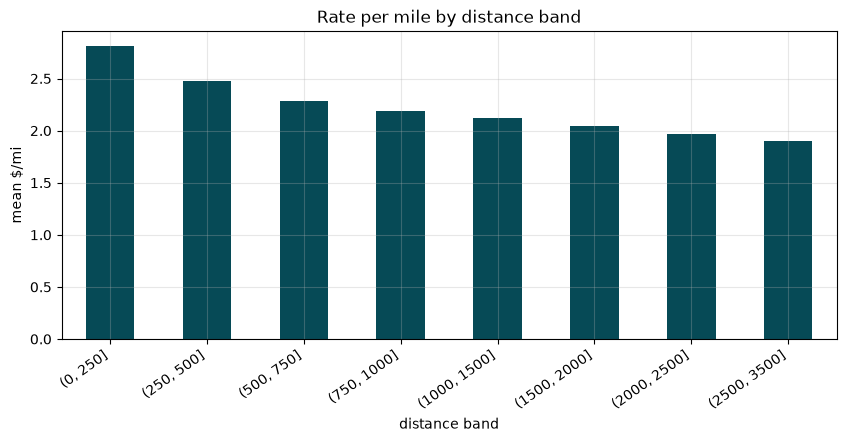

In [29]:
fig, ax = plt.subplots()
by_dist.mean_rpm.plot(kind="bar", ax=ax, color="#064A56")
ax.set_ylabel("mean $/mi"); ax.set_xlabel("distance band")
ax.set_title("Rate per mile by distance band")
plt.xticks(rotation=35, ha="right");

Finding: The average rate per mile decreases as shipment distance increases, from $2.815/mile for loads up to 250 miles to $1.903/mile for loads between 2,500 and 3,500 miles. This indicates a clear short-haul premium. The scatter plot also shows that total posted_rate generally increases with distance, although some shipments have unusually high prices.

Decision: Distance affects both the total shipment price and the rate per mile. Keep both distance and log(distance) as model features to capture potential nonlinear relationships.

# Numeric feature correlations
Two of the columns, `market_index` and `quote_signal`, are opaque market signals. I need to know
how much they carry and whether they are really one signal wearing two hats

In [30]:
num = ["distance", "weight", "market_index", "quote_signal"]
corr = train[num + ["posted_rate"]].corr()
corr.round(3)

,distance,weight,market_index,quote_signal,posted_rate
distance,1.000,0.003,-0.002,-0.057,0.909
weight,0.003,1.000,-0.001,0.008,0.035
market_index,-0.002,-0.001,1.000,-0.068,0.034
quote_signal,-0.057,0.008,-0.068,1.000,-0.040
posted_rate,0.909,0.035,0.034,-0.040,1.000


In [31]:
work = train.assign(rpm=rpm)
work[num + ["rpm"]].corr()["rpm"].drop("rpm").round(3).sort_values()

distance       -0.335
quote_signal    0.049
weight          0.075
market_index    0.083
Name: rpm, dtype: float64

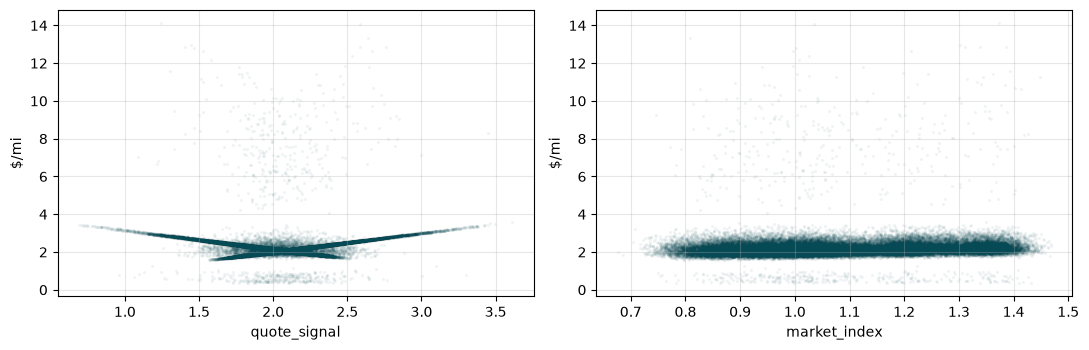

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].scatter(train.quote_signal, rpm, s=2, alpha=0.04, color="#064A56")
axes[0].set_xlabel("quote_signal"); axes[0].set_ylabel("$/mi")
axes[1].scatter(train.market_index, rpm, s=2, alpha=0.04, color="#064A56")
axes[1].set_xlabel("market_index"); axes[1].set_ylabel("$/mi")
plt.tight_layout();

**Finding.** Distance drives most of `posted_rate`, so I use **rate per mile** instead. It removes
the distance effect and shows what the market signals are actually worth.

`market_index` and `quote_signal` are barely correlated (r = −0.07), so they carry different information and I need both for the December chart.

# Categorical values : equipments and lanes
64 cities on each side means up to 4,096 possible lanes over 48,000 training rows. That ratio
decides whether I can target-encode lanes or whether I have to let the model split on the raw
city.

In [33]:
(train.assign(rpm=rpm)
      .groupby("equipment")
      .agg(loads=("rpm", "size"), mean_rpm=("rpm", "mean"), mean_rate=("posted_rate", "mean"))
      .round(3))

,loads,mean_rpm,mean_rate
equipment,,,
Dry Van,27202,2.115,2271.549
Flatbed,8753,2.295,2445.087
Reefer,12045,2.383,2553.637


In [34]:
print("unique pickups:", train.pickup.nunique(), " unique deliveries:", train.delivery.nunique())
lane_sizes = train.groupby(["pickup", "delivery"]).size()
print("distinct lanes observed:", len(lane_sizes))
print(lane_sizes.describe().round(1))

unique pickups: 64  unique deliveries: 64
distinct lanes observed: 4014
count    4014.0
mean       12.0
std         7.2
min         1.0
25%         6.0
50%        10.0
75%        16.0
max        39.0
dtype: float64


In [35]:
# are the coordinates informative, or just a lookup of the city name?
print("distinct pickup_lat per pickup city:", train.groupby("pickup").pickup_lat.nunique().max())
print("distinct delivery_lat per delivery city:", train.groupby("delivery").delivery_lat.nunique().max())

distinct pickup_lat per pickup city: 1
distinct delivery_lat per delivery city: 1


**Finding — two decisions come out of this cell.**

**(a) Coordinates are redundant.** Every city maps to exactly one latitude/longitude pair. The
four coordinate columns are a deterministic lookup of the city name, so feeding both is
duplicated information. I drop the raw coordinates as features and keep the city names as
categoricals. The lookup table itself is still valuable — I need it in section 10 to supply
coordinates for the December rows.

**(b) Lanes are thin.** With ~4,000 observed lanes over 48,000 rows, the typical lane has only
a handful of loads. A per-lane target encoding built on that few observations would overfit
badly. **I let LightGBM split on `pickup` and `delivery` as native categoricals instead**, which
lets it pool across lanes sharing an origin or a destination.

# Time structure
This section decides the shape of the December chart, so it gets the most attention. All 31 chart rows are the same load with only the date changing, whatever I find here *is* that curve.

In [36]:
d = pd.to_datetime(train.date)
work = train.assign(dt=d, rpm=rpm)

monthly = work.groupby(work.dt.dt.to_period("M")).rpm.agg(["mean", "std", "size"])
monthly.round(4)

,mean,std,size
dt,,,
2025-01,2.1002,0.5922,4918
2025-02,2.1229,0.5367,4337
2025-03,2.2061,0.5766,5036
2025-04,2.2103,0.5646,4819
2025-05,2.2601,0.6035,4913
2025-06,2.3325,0.6087,4783
2025-07,2.2560,0.5551,4912
2025-08,2.1886,0.5643,4759
2025-09,2.2297,0.5718,4670


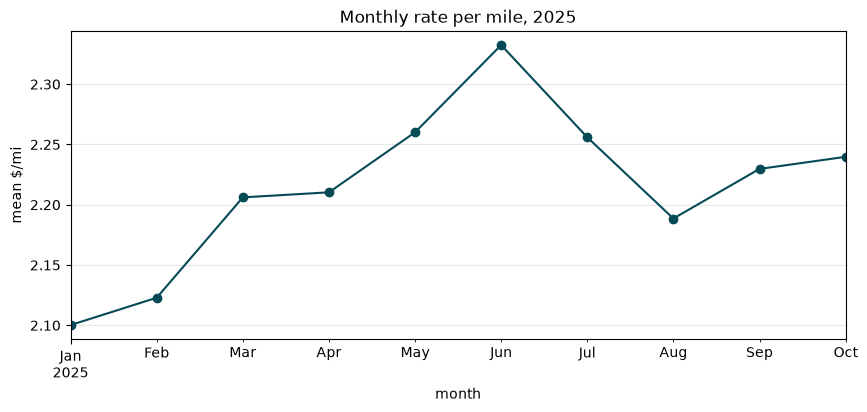

In [37]:
fig, ax = plt.subplots()
monthly["mean"].plot(ax=ax, marker="o", color="#064A56")
ax.set_ylabel("mean $/mi"); ax.set_xlabel("month")
ax.set_title("Monthly rate per mile, 2025");

/var/folders/2y/5t2751fs5hd52xhgl0h6tjt80000gn/T/ipykernel_5010/3228325116.py:1: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  dow = work.groupby(work.dt.dt.dayofweek).rpm.mean()


Mon    2.1964
Tue    2.2134
Wed    2.2484
Thu    2.2446
Fri    2.2149
Sat    2.1957
Sun    2.1923
Name: rpm, dtype: float64

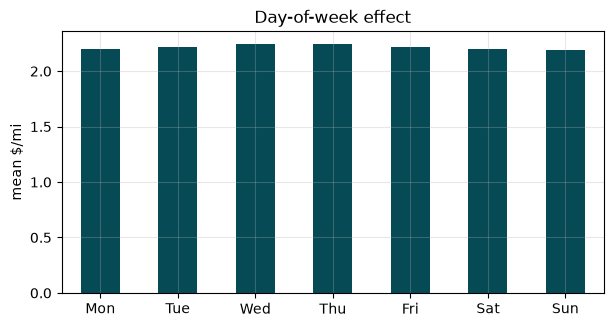

In [38]:
dow = work.groupby(work.dt.dt.dayofweek).rpm.mean()
dow.index = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
fig, ax = plt.subplots(figsize=(7, 3.4))
dow.plot(kind="bar", ax=ax, color="#064A56")
ax.set_ylabel("mean $/mi"); ax.set_title("Day-of-week effect")
plt.xticks(rotation=0)
dow.round(4)

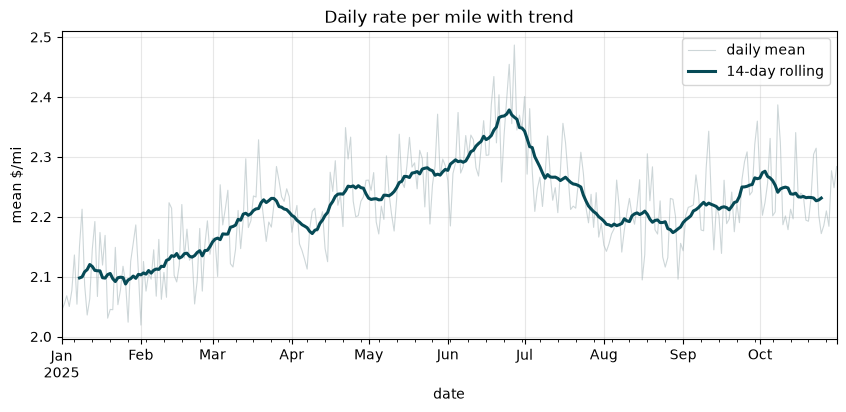

In [39]:
daily = work.groupby("dt").rpm.mean()
fig, ax = plt.subplots()
daily.plot(ax=ax, linewidth=0.8, alpha=0.5, color="#9DAFB3", label="daily mean")
daily.rolling(14, center=True).mean().plot(ax=ax, linewidth=2.2, color="#064A56", label="14-day rolling")
ax.set_ylabel("mean $/mi"); ax.set_xlabel("date")
ax.set_title("Daily rate per mile with trend")
ax.legend();

**Finding.** Monthly rate per mile climbs from 2.10 in January to a June peak of 2.33, then
eases back to about 2.24 by October. Day of week is a smaller effect, roughly 2.19 at the
weekend against 2.25 midweek.

So there is **a genuine but gentle seasonal signal plus a weekly ripple** — no step changes, no
regime breaks.

Two things follow:

- I need both a **linear trend term** (`days_since_2025-01-01`) and **cyclical date features**
  (day of week, day of year, month). The trend term is what lets the model move past the end of
  training into November and December at all; a tree can only ever predict within the range of
  trend values it has seen, so I check this limitation explicitly in `02-model-dev`.
- The December chart should show a soft weekly ripple on a slow trend around
  360 mi x ~2.2 $/mi, so roughly **$790**. A dead-flat line means my date features got dropped
  somewhere in the pipeline; a violent sawtooth means they are overfit. That is my acceptance
  test for section 10.

## 9. Train vs validation drift

Before I trust a model fitted on January-October to score November-December, I check that the
input distributions actually match.

In [40]:
rows = []
for c in ["distance", "weight", "market_index", "quote_signal"]:
    rows.append({
        "feature": c,
        "train_mean": train[c].mean(), "val_mean": val[c].mean(),
        "train_std": train[c].std(), "val_std": val[c].std(),
    })
drift = pd.DataFrame(rows).set_index("feature")
drift["mean_shift_in_sd"] = ((drift.val_mean - drift.train_mean) / drift.train_std)
drift.round(3)

,train_mean,val_mean,train_std,val_std,mean_shift_in_sd
feature,,,,,
distance,1135.857,1141.773,728.564,732.334,0.008
weight,31028.844,30506.636,9391.441,10572.590,-0.056
market_index,1.083,0.927,0.168,0.074,-0.931
quote_signal,2.062,2.051,0.291,0.220,-0.038


In [41]:
eq = pd.DataFrame({
    "train": train.equipment.value_counts(normalize=True),
    "val": val.equipment.value_counts(normalize=True),
})
eq["diff_pp"] = ((eq.val - eq.train) * 100).round(2)
eq.round(4)

,train,val,diff_pp
equipment,,,
Dry Van,0.5667,0.5650,-0.17
Reefer,0.2509,0.2542,0.33
Flatbed,0.1824,0.1808,-0.16


In [42]:
print("pickup cities in val but not train:", set(val.pickup) - set(train.pickup))
print("delivery cities in val but not train:", set(val.delivery) - set(train.delivery))
print("equipment in val but not train:", set(val.equipment) - set(train.equipment))

pickup cities in val but not train: {'San Diego', 'Chicago', 'Allentown', 'Knoxville', 'Laredo', 'Norfolk', 'Charlotte', 'Jackson'}
delivery cities in val but not train: {'San Diego', 'Chicago', 'Allentown', 'Knoxville', 'Laredo', 'Jackson', 'Charlotte', 'Norfolk'}
equipment in val but not train: set()


**Finding.** I am checking two different risks here.

The unseen-category check matters operationally: any city appearing in validation but never in
training would break a categorical encoder at predict time, and I would rather discover that
now than at the final write step.

The `mean_shift_in_sd` column is the covariate-shift check. A market signal that has moved a
meaningful fraction of a standard deviation between the training window and the prediction
window is the clearest warning that a model leaning hard on that feature will degrade — and it
tells me how much weight to put on my own cross-validation numbers.

# Can we even build the December chart rows ? 
The chart file is the trap in this assessment. I check its columns against what my model will
need before I build the model, not after.

In [45]:
december_chart_input

,pickup,delivery,distance,equipment,weight,date,predicted_rate
0,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-01,NaN
1,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-02,NaN
2,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-03,NaN
3,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-04,NaN
4,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-05,NaN
5,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-06,NaN
6,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-07,NaN
7,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-08,NaN
8,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-09,NaN
9,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-10,NaN


In [47]:
needed = set(val.columns) - {"load_id"}
have = set(december_chart_input.columns) - {"predicted_rate"}
print("columns the model sees in validation but NOT in the December file:")
print(sorted(needed - have))

columns the model sees in validation but NOT in the December file:
['delivery_lat', 'delivery_lon', 'market_index', 'pickup_lat', 'pickup_lon', 'quote_signal']


**This is the constraint that shapes the whole pipeline.** The December file has six inputs:
`pickup`, `delivery`, `distance`, `equipment`, `weight`, `date`. It has no coordinates, no
`market_index` and no `quote_signal`.

So any feature pipeline I build has to be able to score a row that lacks those columns, or the
very last step of the assessment fails. I solve both gaps below rather than dropping the
features from the model.

In [48]:
# Gap 1: coordinates. Categoricals section showed city -> coords is exact, so build the lookup.
coords = (pd.concat([
    train[["pickup", "pickup_lat", "pickup_lon"]].rename(
        columns={"pickup": "city", "pickup_lat": "lat", "pickup_lon": "lon"}),
    train[["delivery", "delivery_lat", "delivery_lon"]].rename(
        columns={"delivery": "city", "delivery_lat": "lat", "delivery_lon": "lon"}),
]).drop_duplicates("city").set_index("city"))

print("cities in lookup:", len(coords))
coords.loc[["Lexington", "Fort Wayne"]]

cities in lookup: 64


,lat,lon
city,,
Lexington,36.99152,-84.99876
Fort Wayne,41.31561,-85.36206


In [49]:
# Gap 2: market signals. validation.csv already CONTAINS December rows carrying both.
dec_val = val[val.date >= "2025-12-01"]
print("December rows available in validation.csv:", len(dec_val))

dec_signals = dec_val.groupby("date")[["market_index", "quote_signal"]].median()
print("dates covered:", len(dec_signals))
dec_signals.head()

December rows available in validation.csv: 6164
dates covered: 31


,market_index,quote_signal
date,,
2025-12-01,0.833480,2.05861
2025-12-02,0.914660,2.04049
2025-12-03,0.994420,2.03694
2025-12-04,1.025015,2.06670
2025-12-05,0.974900,2.06752


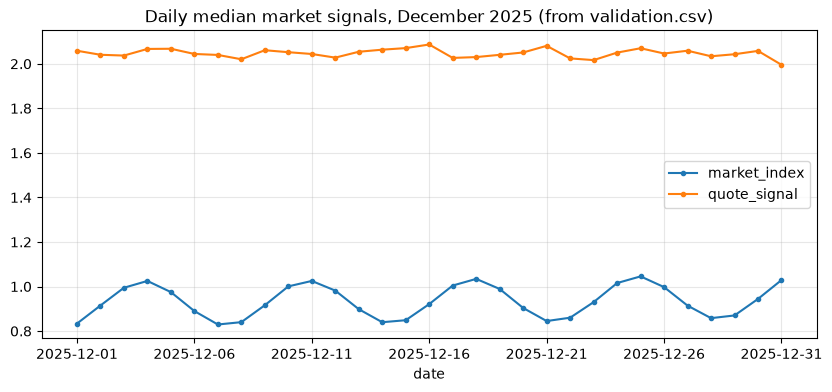

In [50]:
fig, ax = plt.subplots()
dec_signals.plot(ax=ax, marker="o", markersize=3)
ax.set_title("Daily median market signals, December 2025 (from validation.csv)")
ax.set_xlabel("date");

**Finding — the December gap is closable without forecasting.**

- **Coordinates:** solved exactly by the city lookup, since each city has one fixed pair.
- **Market signals:** `validation.csv` already contains 6,164 December rows carrying both
  signals. Taking the per-date median over 2025-12-01 to 2025-12-31 and joining on date gives me
  real supplied values, not an extrapolation.

That second point matters for the report. The obvious alternative — fitting a trend to
`market_index` and projecting it forward — introduces forecast error on top of model error and
is strictly worse when the actual values were handed to me in the data. It also keeps the chart
on **the same model** as my 12,000 submitted predictions, rather than requiring a separate
reduced-feature model.

In [51]:
# Reality check for the chart: what do real Lexington -> Fort Wayne loads cost?
lane = train[(train.pickup == "Lexington") & (train.delivery == "Fort Wayne")]
print("historical loads on this exact lane:", len(lane))
print(lane[["distance", "weight", "posted_rate"]].describe().round(1))
print()
print("mean $/mi on this lane: %.3f" % (lane.posted_rate / lane.distance).mean())
print("implied 360-mile rate:  $%.0f" % (360 * (lane.posted_rate / lane.distance).mean()))

historical loads on this exact lane: 32
       distance   weight  posted_rate
count      32.0     32.0         32.0
mean      363.7  29185.6        856.6
std         8.9   7279.2         63.2
min       346.3  16195.0        757.9
25%       358.2  23955.2        796.7
50%       362.3  27336.5        848.6
75%       368.2  36636.0        912.6
max       384.5  41138.0        973.8

mean $/mi on this lane: 2.355
implied 360-mile rate:  $848


**Finding.** There are 32 historical loads on the exact Lexington to Fort Wayne lane. Their mean
rate per mile, multiplied by the fixed 360 miles, gives me a concrete dollar figure to check my
31 December predictions against. If the chart lands far away from it, the feature reconstruction
above is wrong and I debug before submitting — not after.

## Summary of Decisions

- Treat the task as pure forecasting because training and validation dates do not overlap.
- Replace negative `weight` values with their absolute values.
- Impute missing `weight` and `market_index` using training-set means; retain missing-value indicators.
- Predict `rate per mile` rather than raw `posted_rate`, then multiply by distance.
- Use log transformation for the target to reduce right skew.
- Keep distance and `log(distance)` to capture short-haul pricing effects.
- Use native categorical handling for `pickup`, `delivery`, and `equipment`; do not target-encode sparse lanes.
- Drop coordinates as model features because they duplicate city identities.
- Add trend, day-of-week, month, day-of-year, and cyclical date features.
- Use actual December daily market signals from `validation.csv`.
- Reconstruct December coordinates from the city-to-coordinate lookup.
- Validate using time-based splits and trim extreme rate-per-mile values only within training folds.